# Praktikum Analisis Sentimen Twitter dengan Neural Network (MLP)

Alur: Load data (hasil crawling) → Cleansing → Pelabelan rule-based → Distribusi → WordCloud → TF-IDF + MLP → Evaluasi → Prediksi teks baru.

> Langkah 1 (crawling) dilewati karena data sudah tersedia di `Data_Kualitas_Udara.xls` (topik: kualitas udara / kabut asap; kolom: `created_at`, `username`, `full_text`).

In [19]:
# !pip install pandas numpy matplotlib scikit-learn wordcloud xlrd
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings("ignore")

## Langkah 1 — Load Data (hasil crawling)

In [20]:
# .xls lama dibaca dengan engine xlrd (pip install xlrd)
df = pd.read_excel("Data_Kualitas_Udara.xls", engine="xlrd")
# jika datanya CSV: df = pd.read_csv("tweet_data.csv")
df = df[["created_at", "username", "full_text"]]
print("Jumlah data:", len(df))
df.head()

Jumlah data: 1500


,created_at,username,full_text
0,2026-11-14T06:19:29.000Z,JohnMunstar,@MilahPass Semoga di daerah Yg terkena Karhutl...
1,2026-11-14T05:40:00.000Z,Melihat_Indo,Makin Panas! Dikritik Soal Sensor Konten Benca...
2,2026-11-14T05:04:38.000Z,redbold7177,12:02 pm polusi udara di jakut yg berasal dr k...
3,2026-11-14T05:00:01.000Z,CariSini79113,"Bukan karena prestasi yang bikin bangga, kali ..."
4,2026-11-14T04:53:50.000Z,halo_bandung,Pak Wali juga mengajak warga meningkatkan kewa...


## Langkah 3 — Pemrosesan Teks (Cleansing)
Menghapus URL, mention, hashtag, simbol, angka; case folding; merapikan spasi.

In [21]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)   # URL
    text = re.sub(r"@\w+", " ", text)                    # mention
    text = re.sub(r"#\w+", " ", text)                    # hashtag
    text = re.sub(r"\brt\b", " ", text, flags=re.I)      # penanda retweet
    text = text.lower()                                  # case folding
    text = re.sub(r"[^a-z\s]", " ", text)                # simbol, angka, emoji
    text = re.sub(r"\s+", " ", text).strip()             # spasi berlebih
    return text

df = df.dropna(subset=["full_text"]).copy()
df["clean_text"] = df["full_text"].apply(clean_text)
df = df[df["clean_text"].str.len() > 0].drop_duplicates(subset="clean_text").reset_index(drop=True)
print("Jumlah data setelah cleansing:", len(df))
df[["full_text", "clean_text"]].head(10)

Jumlah data setelah cleansing: 1439


,full_text,clean_text
0,@MilahPass Semoga di daerah Yg terkena Karhutl...,semoga di daerah yg terkena karhutla juga turu...
1,Makin Panas! Dikritik Soal Sensor Konten Benca...,makin panas dikritik soal sensor konten bencan...
2,12:02 pm polusi udara di jakut yg berasal dr k...,pm polusi udara di jakut yg berasal dr kawasan...
3,"Bukan karena prestasi yang bikin bangga, kali ...",bukan karena prestasi yang bikin bangga kali i...
4,Pak Wali juga mengajak warga meningkatkan kewa...,pak wali juga mengajak warga meningkatkan kewa...
5,"@Delynn_JKT48 Hujan??? Disini 39° del, apa itu...",hujan disini del apa itu hujan panaaas disana ...
6,"Sejuknya dapat, udara bersihnya juga! ❄️💙\n\nH...",sejuknya dapat udara bersihnya juga hisense x ...
7,🚨JANGAN LUPAKAN KARHUTLA: IBU PANIK CARI ANAK ...,jangan lupakan karhutla ibu panik cari anak di...
8,9:55 am beruntunglah warga pusat jakarta tdk t...,am beruntunglah warga pusat jakarta tdk terpap...
9,update karhutla dari ferry irwandi\n\njadi gin...,update karhutla dari ferry irwandi jadi gini g...


## Langkah 4 — Pelabelan Sentimen (Rule-Based)
Daftar kata di bawah bisa disesuaikan dengan topik yang kamu pilih.

In [22]:
POSITIF = "bersih, sehat, segar, sejuk, nyaman, jernih, baik, bagus, membaik, lega, aman, alhamdulillah, bersyukur, syukur, semoga, semangat, pulih, terbantu, bantuan, membantu, solusi, berhasil, sukses, apresiasi, peduli, dukung, kondusif, lancar, mantap, hebat, puas, terimakasih, makasih, mereda, reda, turun hujan, hujan lebat, hujan deras, cerah, normal, kembali normal, udara bersih, kualitas baik, mendukung, komitmen, inovasi, efektif, optimis, harapan"
NEGATIF = "buruk, parah, bahaya, berbahaya, beracun, racun, tercemar, pencemaran, kotor, pekat, tebal, sesak, sesek, batuk, ispa, penyakit, kanker, menderita, derita, korban, kecewa, kesal, marah, muak, gagal, lalai, lambat, abai, krisis, darurat, bencana, rusak, merusak, gangguan, mengganggu, terganggu, keluhan, mengeluh, khawatir, cemas, panik, menyesakkan, tidak sehat, tak sehat, tidak baik, tidak aman, tidak layak, kritis, mematikan, kematian, meninggal, sakit, perih, pedih, panas, gerah, kabur, menyiksa, tersiksa, bohong, salah, tinggi pm"
positif_words = {w.strip() for w in POSITIF.split(",") if w.strip()}
negatif_words = {w.strip() for w in NEGATIF.split(",") if w.strip()}

def label_sentiment(text):
    # frasa terpanjang dicocokkan lebih dulu (mis. 'tidak sehat' = negatif, bukan 'sehat' = positif)
    t = " " + text + " "
    terms = sorted([(w, 1) for w in positif_words] + [(w, -1) for w in negatif_words],
                   key=lambda x: -len(x[0]))
    pos = neg = 0
    for w, sign in terms:
        k = t.count(f" {w} ")
        if k:
            if sign > 0:
                pos += k
            else:
                neg += k
            t = t.replace(f" {w} ", "  ")
    if pos > neg:
        return "positif"
    if neg > pos:
        return "negatif"
    return "netral"

df["sentimen"] = df["clean_text"].apply(label_sentiment)
df[["clean_text", "sentimen"]].head(10)

,clean_text,sentimen
0,semoga di daerah yg terkena karhutla juga turu...,positif
1,makin panas dikritik soal sensor konten bencan...,negatif
2,pm polusi udara di jakut yg berasal dr kawasan...,negatif
3,bukan karena prestasi yang bikin bangga kali i...,negatif
4,pak wali juga mengajak warga meningkatkan kewa...,netral
5,hujan disini del apa itu hujan panaaas disana ...,positif
6,sejuknya dapat udara bersihnya juga hisense x ...,positif
7,jangan lupakan karhutla ibu panik cari anak di...,negatif
8,am beruntunglah warga pusat jakarta tdk terpap...,netral
9,update karhutla dari ferry irwandi jadi gini g...,positif


## Langkah 5 — Analisis Distribusi Sentimen

sentimen
positif    282
netral     706
negatif    451
Name: count, dtype: int64


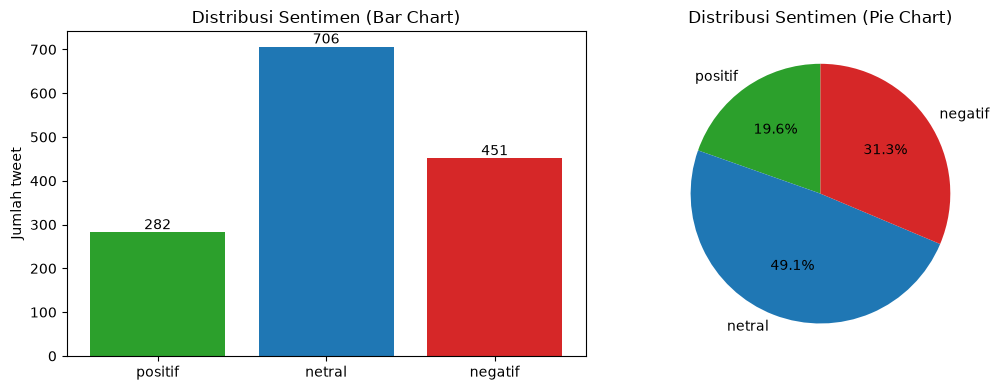

In [23]:
LABELS = ["positif", "netral", "negatif"]
COLORS = ["#2ca02c", "#1f77b4", "#d62728"]
counts = df["sentimen"].value_counts().reindex(LABELS).fillna(0).astype(int)
print(counts)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars = axes[0].bar(counts.index, counts.values, color=COLORS)
axes[0].bar_label(bars)
axes[0].set_title("Distribusi Sentimen (Bar Chart)")
axes[0].set_ylabel("Jumlah tweet")

nz = counts[counts > 0]
axes[1].pie(nz.values, labels=nz.index, autopct="%1.1f%%", startangle=90,
            colors=[COLORS[LABELS.index(l)] for l in nz.index])
axes[1].set_title("Distribusi Sentimen (Pie Chart)")
plt.tight_layout()
plt.show()

## Langkah 6 — Visualisasi WordCloud per Sentimen

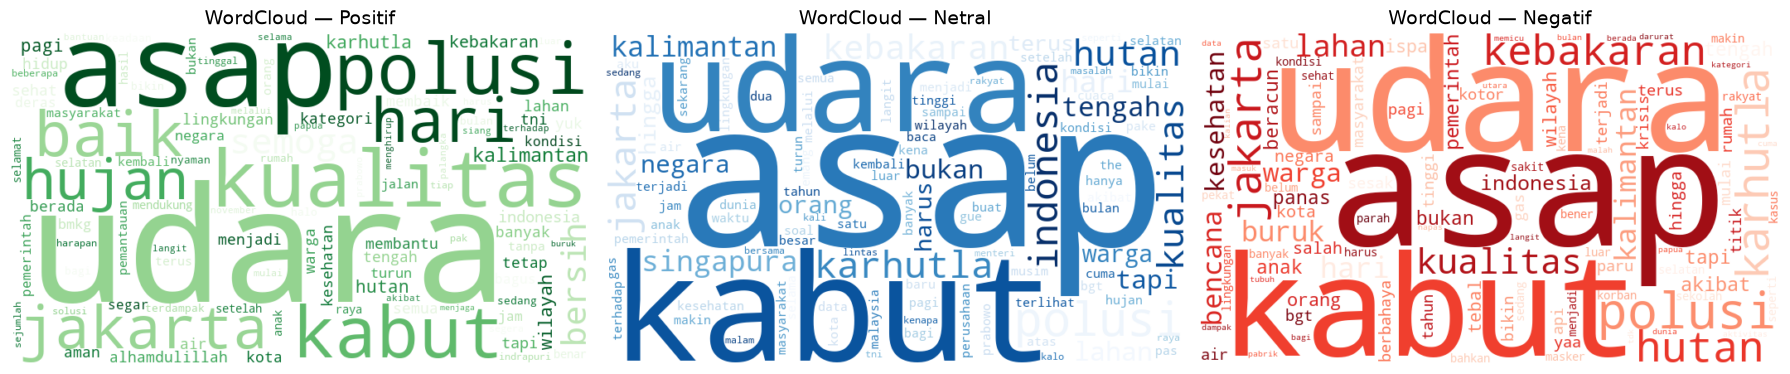

In [24]:
stopwords = set("""
yang dan di ke dari ini itu untuk dengan pada adalah atau juga tidak ada akan sudah
saya kami kita kamu dia mereka nya aja ya sih deh dong lah kok yg dgn utk krn karena
jadi bisa lagi udah gak ga nggak tak mau sama oleh dalam sebagai bahwa para lebih
masih sangat banget pun saat ketika apa siapa mana kalau jika agar supaya rt amp
""".split())

cmaps = {"positif": "Greens", "netral": "Blues", "negatif": "Reds"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab in zip(axes, LABELS):
    text = " ".join(df.loc[df["sentimen"] == lab, "clean_text"])
    words = [w for w in text.split() if w not in stopwords and len(w) > 2]
    ax.axis("off")
    ax.set_title(f"WordCloud — {lab.capitalize()}", fontsize=14)
    if not words:
        ax.text(0.5, 0.5, "Tidak ada data", ha="center")
        continue
    wc = WordCloud(width=700, height=400, background_color="white",
                   colormap=cmaps[lab], max_words=100).generate_from_frequencies(Counter(words))
    ax.imshow(wc, interpolation="bilinear")
plt.tight_layout()
plt.show()

## Langkah 7 — Model Neural Network (MLP)
Split 80:20, TF-IDF, MLP (ReLU, Adam, 100 neuron hidden).

Data latih: 1151 | Data uji: 288
Dimensi fitur TF-IDF: (1151, 5609)
Iterasi training: 274


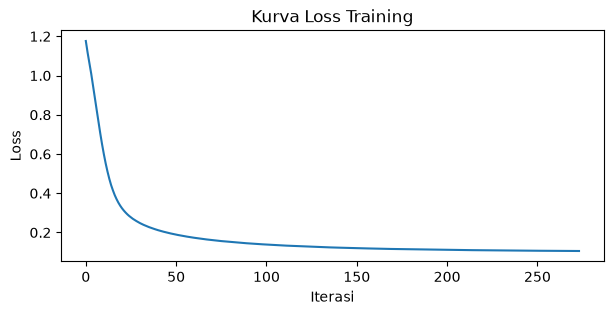

In [25]:
X = df["clean_text"]
y = df["sentimen"]

stratify = y if y.value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=stratify)
print("Data latih:", len(X_train), "| Data uji:", len(X_test))

# min_df=2 membuang kata yang hanya muncul 1x (noise), sublinear_tf meredam kata yang terlalu sering
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("Dimensi fitur TF-IDF:", X_train_tfidf.shape)

mlp = MLPClassifier(hidden_layer_sizes=(100,), activation="relu", solver="adam",
                    alpha=0.1, max_iter=300, random_state=42)   # alpha = regularisasi L2, mengurangi overfitting
mlp.fit(X_train_tfidf, y_train)
y_pred = mlp.predict(X_test_tfidf)
print("Iterasi training:", mlp.n_iter_)

plt.figure(figsize=(7, 3))
plt.plot(mlp.loss_curve_)
plt.title("Kurva Loss Training")
plt.xlabel("Iterasi"); plt.ylabel("Loss")
plt.show()

## Langkah 8 — Evaluasi Model

,Metrik,Nilai
0,Akurasi,0.7431
1,Presisi,0.7441
2,Recall,0.7431
3,F1-Score,0.7393



Classification Report:
              precision    recall  f1-score   support

     negatif       0.75      0.77      0.76        90
      netral       0.74      0.81      0.77       141
     positif       0.76      0.54      0.63        57

    accuracy                           0.74       288
   macro avg       0.75      0.71      0.72       288
weighted avg       0.74      0.74      0.74       288



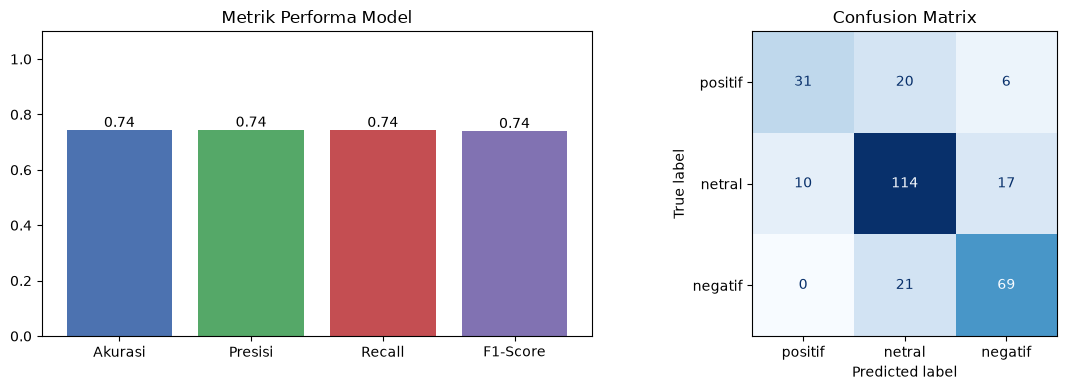

In [26]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

metrics_df = pd.DataFrame({
    "Metrik": ["Akurasi", "Presisi", "Recall", "F1-Score"],
    "Nilai": [acc, prec, rec, f1]
})
display(metrics_df.style.format({"Nilai": "{:.4f}"}))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cls = [l for l in LABELS if l in mlp.classes_]
cm = confusion_matrix(y_test, y_pred, labels=cls)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars = axes[0].bar(metrics_df["Metrik"], metrics_df["Nilai"],
                   color=["#4c72b0", "#55a868", "#c44e52", "#8172b2"])
axes[0].bar_label(bars, fmt="%.2f")
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Metrik Performa Model")
ConfusionMatrixDisplay(cm, display_labels=cls).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Confusion Matrix")
plt.tight_layout()
plt.show()

## Langkah 9 — Prediksi Teks Baru

In [27]:
EMOJI = {"positif": "😊", "netral": "😐", "negatif": "😠"}

def predict_sentiment(teks):
    cleaned = clean_text(teks)
    proba = mlp.predict_proba(tfidf.transform([cleaned]))[0]
    pred = mlp.classes_[int(np.argmax(proba))]
    print(f"Teks asli    : {teks}")
    print(f"Teks bersih  : {cleaned}")
    print(f"Prediksi     : {EMOJI[pred]} {pred.upper()}")
    for c, p in zip(mlp.classes_, proba):
        print(f"  {EMOJI[c]} {c:<8}: {p:.2%}")
    print("-" * 50)

predict_sentiment("udara pagi ini bersih dan sehat setelah hujan, alhamdulillah")
predict_sentiment("kabut asap parah, warga sesak napas dan menderita ispa")
predict_sentiment("laporan indeks kualitas udara jakarta hari ini pukul tujuh")

Teks asli    : udara pagi ini bersih dan sehat setelah hujan, alhamdulillah
Teks bersih  : udara pagi ini bersih dan sehat setelah hujan alhamdulillah
Prediksi     : 😊 POSITIF
  😠 negatif : 0.01%
  😐 netral  : 0.15%
  😊 positif : 99.84%
--------------------------------------------------
Teks asli    : kabut asap parah, warga sesak napas dan menderita ispa
Teks bersih  : kabut asap parah warga sesak napas dan menderita ispa
Prediksi     : 😠 NEGATIF
  😠 negatif : 99.99%
  😐 netral  : 0.00%
  😊 positif : 0.01%
--------------------------------------------------
Teks asli    : laporan indeks kualitas udara jakarta hari ini pukul tujuh
Teks bersih  : laporan indeks kualitas udara jakarta hari ini pukul tujuh
Prediksi     : 😠 NEGATIF
  😠 negatif : 69.57%
  😐 netral  : 26.55%
  😊 positif : 3.88%
--------------------------------------------------
